# CS6120 - Natural Language Processing
## Written and Prepared by: Amir Tahmasebi

# Deep NLP Tutorial with Visualizations and Animations

In this extended tutorial, we'll demonstrate:
1. **RNN (GRU & LSTM)** for text classification, including:
   - **Training/validation curves** (static plots)
   - An **animation** of training accuracy per epoch.
2. **CNN for text classification**, also with a quick accuracy/loss plot.
3. **Transformers** with Hugging Face for sentiment classification, plus a small **visualization** of results.

We keep the datasets tiny/synthetic so training is **fast**. Real-world tasks would typically require larger datasets and more epochs.

## Table of Contents
1. [Imports and Setup](#1.-Imports-and-Setup)
2. [Synthetic Data Preparation](#2.-Synthetic-Data-Preparation)
3. [GRU Model](#3.-GRU-Model)
   - 3.1 [Static Plot of Training Curves](#3.1-Static-Plot-of-Training-Curves)
   - 3.2 [Animation of Accuracy](#3.2-Animation-of-Accuracy)
4. [LSTM Model](#4.-LSTM-Model)
5. [CNN for Text Classification](#5.-CNN-for-Text-Classification)
6. [Transformers Example](#6.-Transformers-Example)

## 1. Imports and Setup
We'll need:
- `numpy` for data manipulation.
- `matplotlib` for plotting and (optionally) animations.
- `tensorflow` (Keras) for building and training GRU, LSTM, and CNN models.
- `transformers` for the Hugging Face pipeline.

If you see import errors, install missing libraries (e.g. `pip install tensorflow transformers`).

In [1]:
# If you want interactive animations in some environments (like classic Jupyter Notebook), you can try:
# %matplotlib notebook
# For static inline animations, you can do:
# %matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("Using TensorFlow version:", tf.__version__)


2025-06-17 22:30:29.515982: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


TypeError: Descriptors cannot be created directly.
If this call came from a _pb2.py file, your generated code is out of date and must be regenerated with protoc >= 3.19.0.
If you cannot immediately regenerate your protos, some other possible workarounds are:
 1. Downgrade the protobuf package to 3.20.x or lower.
 2. Set PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION=python (but this will use pure-Python parsing and will be much slower).

More information: https://developers.google.com/protocol-buffers/docs/news/2022-05-06#python-updates

## 2. Synthetic Data Preparation
We’ll create a small dataset of **2000** sequences (each length 10). The vocabulary size is **50** token IDs.
We label each sequence as **1** if the sum of its tokens is above a threshold, else **0**. This is an **artificial** classification rule, but it will suffice to illustrate training and visualization.

We split into a **train** (80%) and **test** (20%) set.

In [2]:
# Generate synthetic data
num_samples = 2000
seq_length = 10
vocab_size = 50

X_data = np.random.randint(0, vocab_size, size=(num_samples, seq_length))
threshold = vocab_size * seq_length / 2.0  # e.g. if sum > 250 => label=1
y_data = (X_data.sum(axis=1) > threshold).astype(int)

split_index = int(num_samples * 0.8)
X_train, X_test = X_data[:split_index], X_data[split_index:]
y_train, y_test = y_data[:split_index], y_data[split_index:]

print(f"Training size: {len(X_train)}, Test size: {len(X_test)}")

Training size: 1600, Test size: 400


## 3. GRU Model
We’ll define a small GRU-based classifier with:
- An **Embedding** layer
- A **GRU** layer
- A **Dense** output for binary classification

We’ll train for a few epochs (just to demonstrate), then we’ll visualize training curves **and** create a short **animation** showing how accuracy changes over time.

In [3]:
# Hyperparameters
embedding_dim = 16
rnn_units = 32
batch_size = 32
epochs = 5  # slightly more epochs to see some curve changes

# Define GRU model
gru_model = keras.Sequential([
    layers.Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=seq_length),
    layers.GRU(rnn_units),
    layers.Dense(1, activation='sigmoid')
])

gru_model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

gru_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 10, 16)            800       
                                                                 


2025-02-22 10:38:10.130300: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


 gru (GRU)                   (None, 32)                4800      
                                                                 
 dense (Dense)               (None, 1)                 33        
                                                                 
Total params: 5,633
Trainable params: 5,633
Non-trainable params: 0
_________________________________________________________________


In [4]:
# Train GRU model
history_gru = gru_model.fit(
    X_train, y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5
40/40 [==============================] - 2s 11ms/step - loss: 0.6815 - accuracy: 0.5703 - val_loss: 0.6703 - val_accuracy: 0.5750
Epoch 2/5
40/40 [==============================] - 0s 3ms/step - loss: 0.6220 - accuracy: 0.6000 - val_loss: 0.4910 - val_accuracy: 0.7969
Epoch 3/5
40/40 [==============================] - 0s 3ms/step - loss: 0.3649 - accuracy: 0.8805 - val_loss: 0.3054 - val_accuracy: 0.9031
Epoch 4/5
40/40 [==============================] - 0s 3ms/step - loss: 0.2467 - accuracy: 0.9172 - val_loss: 0.2130 - val_accuracy: 0.9406
Epoch 5/5
40/40 [==============================] - 0s 3ms/step - loss: 0.1822 - accuracy: 0.9367 - val_loss: 0.1535 - val_accuracy: 0.9688


### 3.1 Static Plot of Training Curves
Let’s plot training & validation accuracy and loss across epochs.

<IPython.core.display.Javascript object>


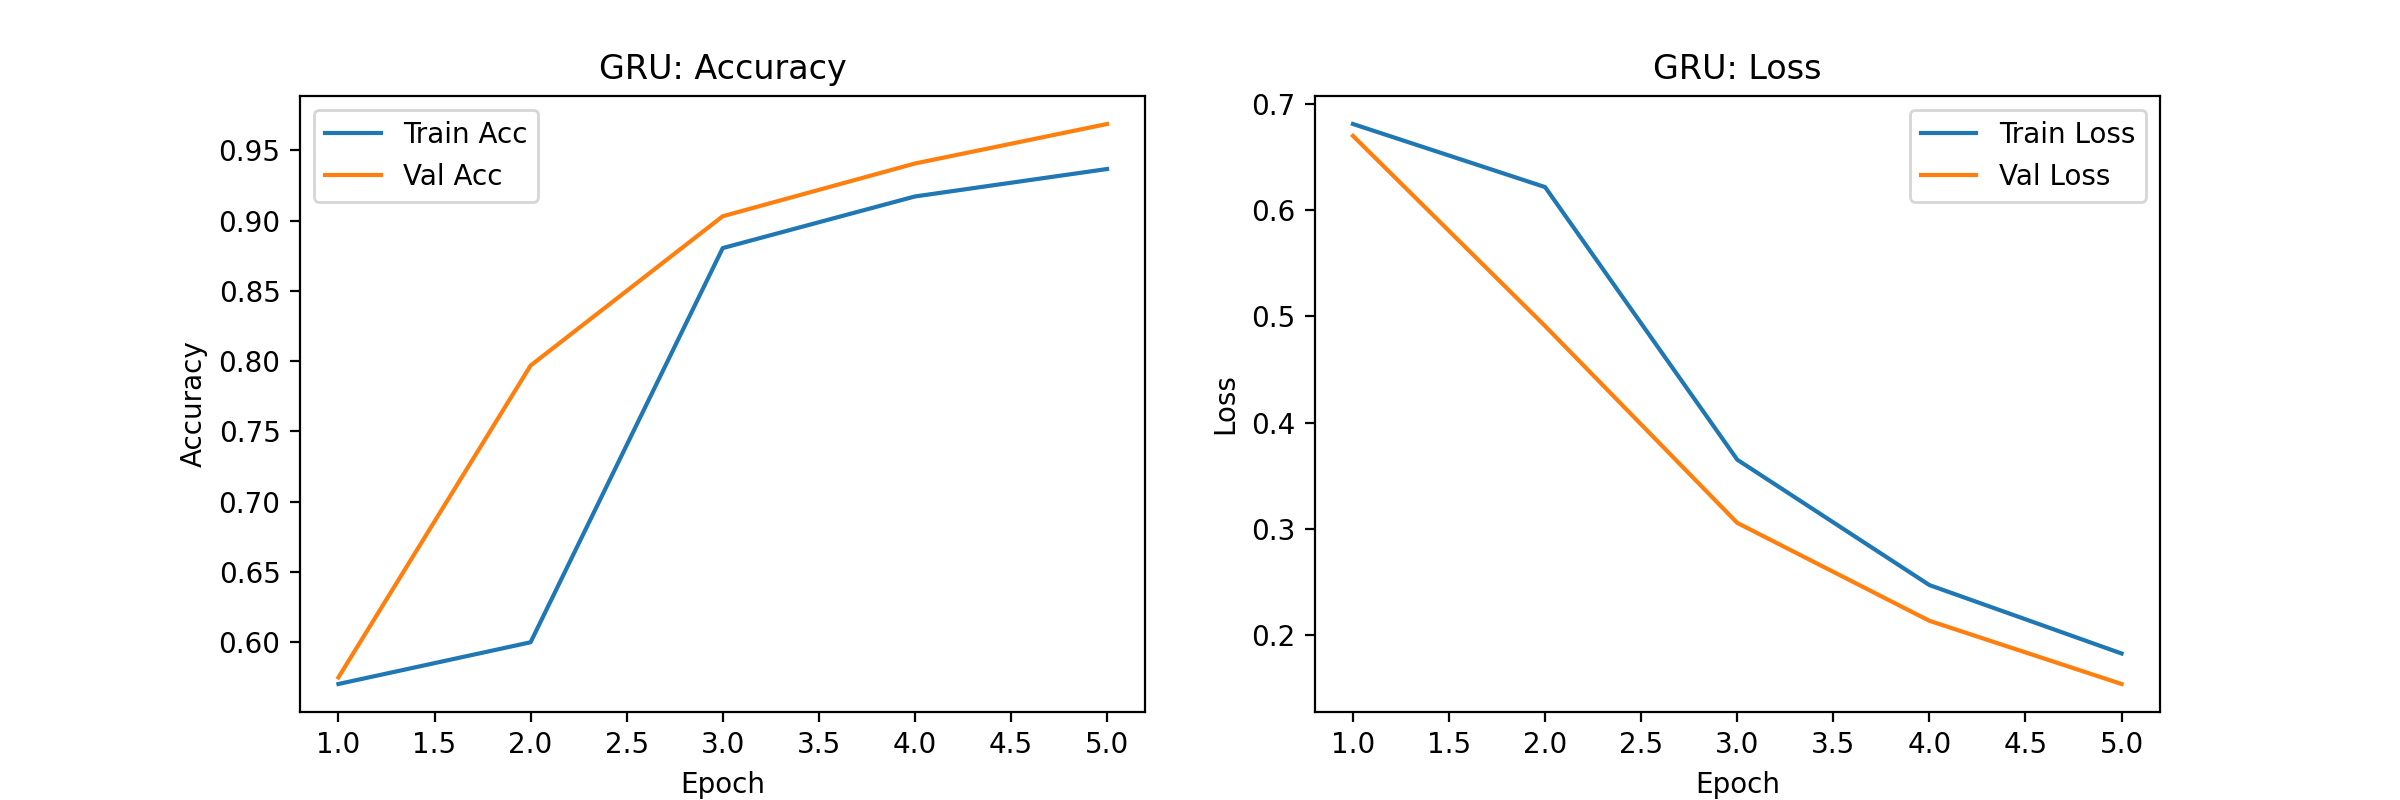

In [5]:
acc = history_gru.history['accuracy']
val_acc = history_gru.history['val_accuracy']
loss = history_gru.history['loss']
val_loss = history_gru.history['val_loss']
epochs_range = range(1, epochs + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label='Train Acc')
plt.plot(epochs_range, val_acc, label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('GRU: Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label='Train Loss')
plt.plot(epochs_range, val_loss, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('GRU: Loss')
plt.legend()

plt.show()

### 3.2 Animation of Accuracy
We can create a simple **animation** (using `matplotlib.animation.FuncAnimation`) to visualize how **training** and **validation** accuracy evolves across epochs. This is purely illustrative.

> **Note**: If running in an environment that doesn’t show animations automatically, you can do:
>
```python
%matplotlib notebook
```
>
or display the animation as HTML using `HTML(ani.to_jshtml())`.

<IPython.core.display.Javascript object>


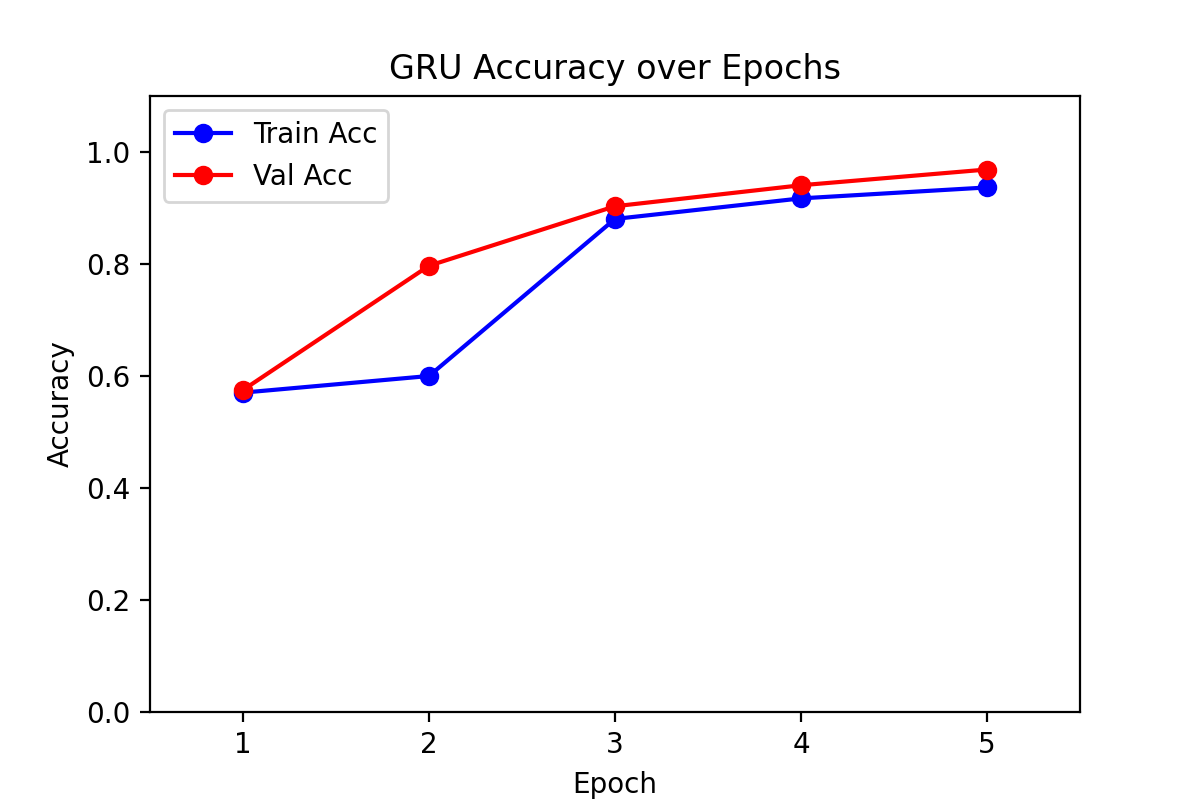

In [6]:
# We'll animate the accuracy curves.

train_acc = history_gru.history['accuracy']
val_acc = history_gru.history['val_accuracy']
epochs_list = np.arange(1, epochs+1)

fig, ax = plt.subplots(figsize=(6,4))
line_train, = ax.plot([], [], 'bo-', label='Train Acc')
line_val, = ax.plot([], [], 'ro-', label='Val Acc')

ax.set_xlim(0.5, epochs + 0.5)
ax.set_ylim(0, 1.1)
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy')
ax.set_title('GRU Accuracy over Epochs')
ax.legend()

def init():
    line_train.set_data([], [])
    line_val.set_data([], [])
    return line_train, line_val

def animate(i):
    # i goes from 0 to epochs-1
    xdata = epochs_list[:i+1]
    ydata_train = train_acc[:i+1]
    ydata_val = val_acc[:i+1]
    line_train.set_data(xdata, ydata_train)
    line_val.set_data(xdata, ydata_val)
    return line_train, line_val

ani = animation.FuncAnimation(fig, animate, frames=epochs, init_func=init,
                              interval=700, blit=True, repeat=False)

# If your environment supports live inline animations, the next line might just show it.
# Otherwise, let's convert to HTML:
HTML(ani.to_jshtml())

In [7]:
# Evaluate the GRU on the test set
loss_gru, acc_gru = gru_model.evaluate(X_test, y_test)
print(f"GRU - Test Loss: {loss_gru:.4f}, Test Acc: {acc_gru:.4f}")

13/13 [==============================] - 0s 2ms/step - loss: 0.1591 - accuracy: 0.9500
GRU - Test Loss: 0.1591, Test Acc: 0.9500


## 4. LSTM Model
Now, we create a similar model using **LSTM** instead of **GRU**. We'll keep the same hyperparameters for a fair comparison.

In [8]:
lstm_model = keras.Sequential([
    layers.Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=seq_length),
    layers.LSTM(rnn_units),
    layers.Dense(1, activation='sigmoid')
])

lstm_model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

lstm_model.summary()

# Train for the same number of epochs
history_lstm = lstm_model.fit(
    X_train, y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.2,
    verbose=1
)


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_1 (Embedding)     (None, 10, 16)            800       
                                                                 
 lstm (LSTM)                 (None, 32)                6272      
                                                                 
 dense_1 (Dense)             (None, 1)                 33        
                                                                 
Total params: 7,105
Trainable params: 7,105
Non-trainable params: 0
_________________________________________________________________
Epoch 1/5
40/40 [==============================] - 2s 11ms/step - loss: 0.6762 - accuracy: 0.5719 - val_loss: 0.6442 - val_accuracy: 0.5750
Epoch 2/5
40/40 [==============================] - 0s 3ms/step - loss: 0.5294 - accuracy: 0.7117 - val_loss: 0.4673 - val_accuracy: 0.8031
Epoch 3/5
40/40 [====================

<IPython.core.display.Javascript object>


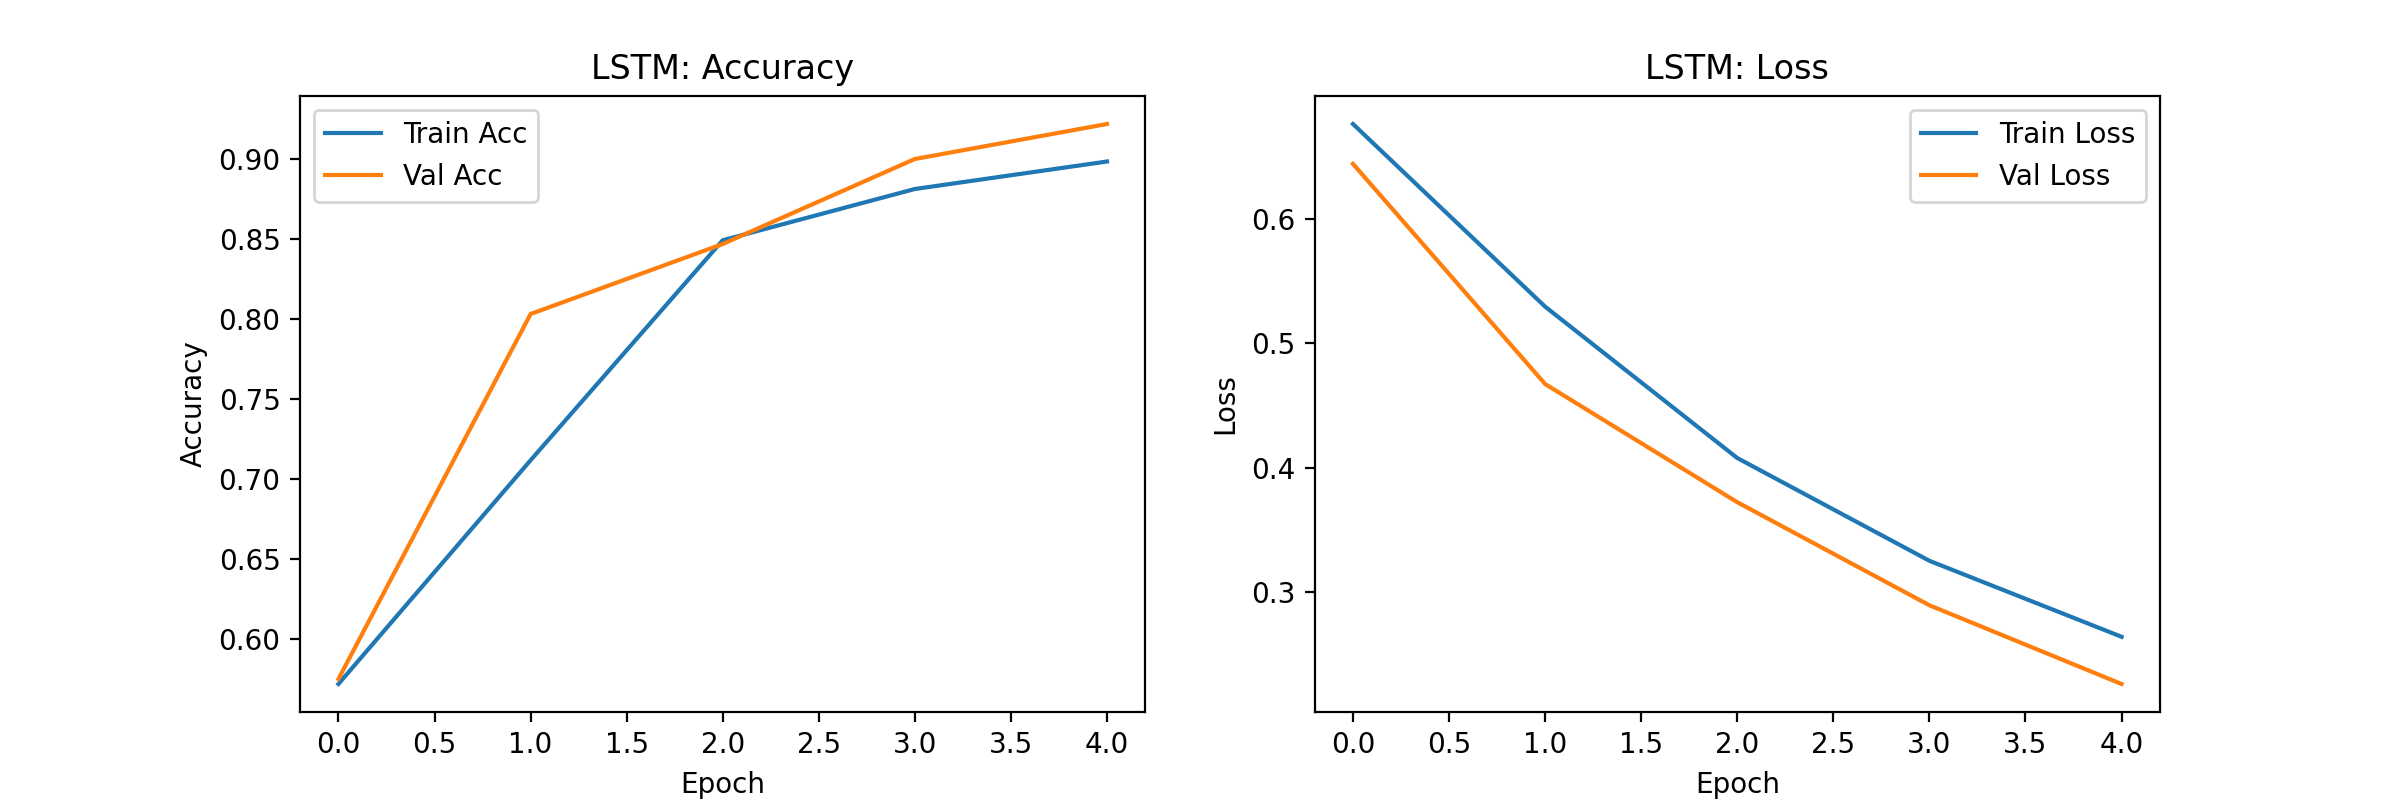

13/13 [==============================] - 0s 2ms/step - loss: 0.2262 - accuracy: 0.9150
LSTM - Test Loss: 0.2262, Test Acc: 0.9150


In [9]:
# Quick plot of LSTM training curves
plt.figure(figsize=(12, 4))

plt.subplot(1,2,1)
plt.plot(history_lstm.history['accuracy'], label='Train Acc')
plt.plot(history_lstm.history['val_accuracy'], label='Val Acc')
plt.title('LSTM: Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history_lstm.history['loss'], label='Train Loss')
plt.plot(history_lstm.history['val_loss'], label='Val Loss')
plt.title('LSTM: Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Evaluate on test
loss_lstm, acc_lstm = lstm_model.evaluate(X_test, y_test)
print(f"LSTM - Test Loss: {loss_lstm:.4f}, Test Acc: {acc_lstm:.4f}")

## 5. CNN for Text Classification
We’ll do a simple 1D CNN:
1. **Embedding** layer
2. **Conv1D** (filters=32, kernel_size=3)
3. **GlobalMaxPooling1D**
4. **Dense** output (sigmoid)

Then we’ll visualize the results similarly.

In [10]:
cnn_model = keras.Sequential([
    layers.Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=seq_length),
    layers.Conv1D(filters=32, kernel_size=3, padding='valid', activation='relu'),
    layers.GlobalMaxPooling1D(),
    layers.Dense(1, activation='sigmoid')
])

cnn_model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

cnn_model.summary()

history_cnn = cnn_model.fit(
    X_train, y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.2,
    verbose=1
)


Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_2 (Embedding)     (None, 10, 16)            800       
                                                                 
 conv1d (Conv1D)             (None, 8, 32)             1568      
                                                                 
 global_max_pooling1d (Globa  (None, 32)               0         
 lMaxPooling1D)                                                  
                                                                 
 dense_2 (Dense)             (None, 1)                 33        
                                                                 
Total params: 2,401
Trainable params: 2,401
Non-trainable params: 0
_________________________________________________________________
Epoch 1/5
40/40 [==============================] - 1s 6ms/step - loss: 0.6836 - accuracy: 0.5789 - val_loss: 0.6745 - 

<IPython.core.display.Javascript object>


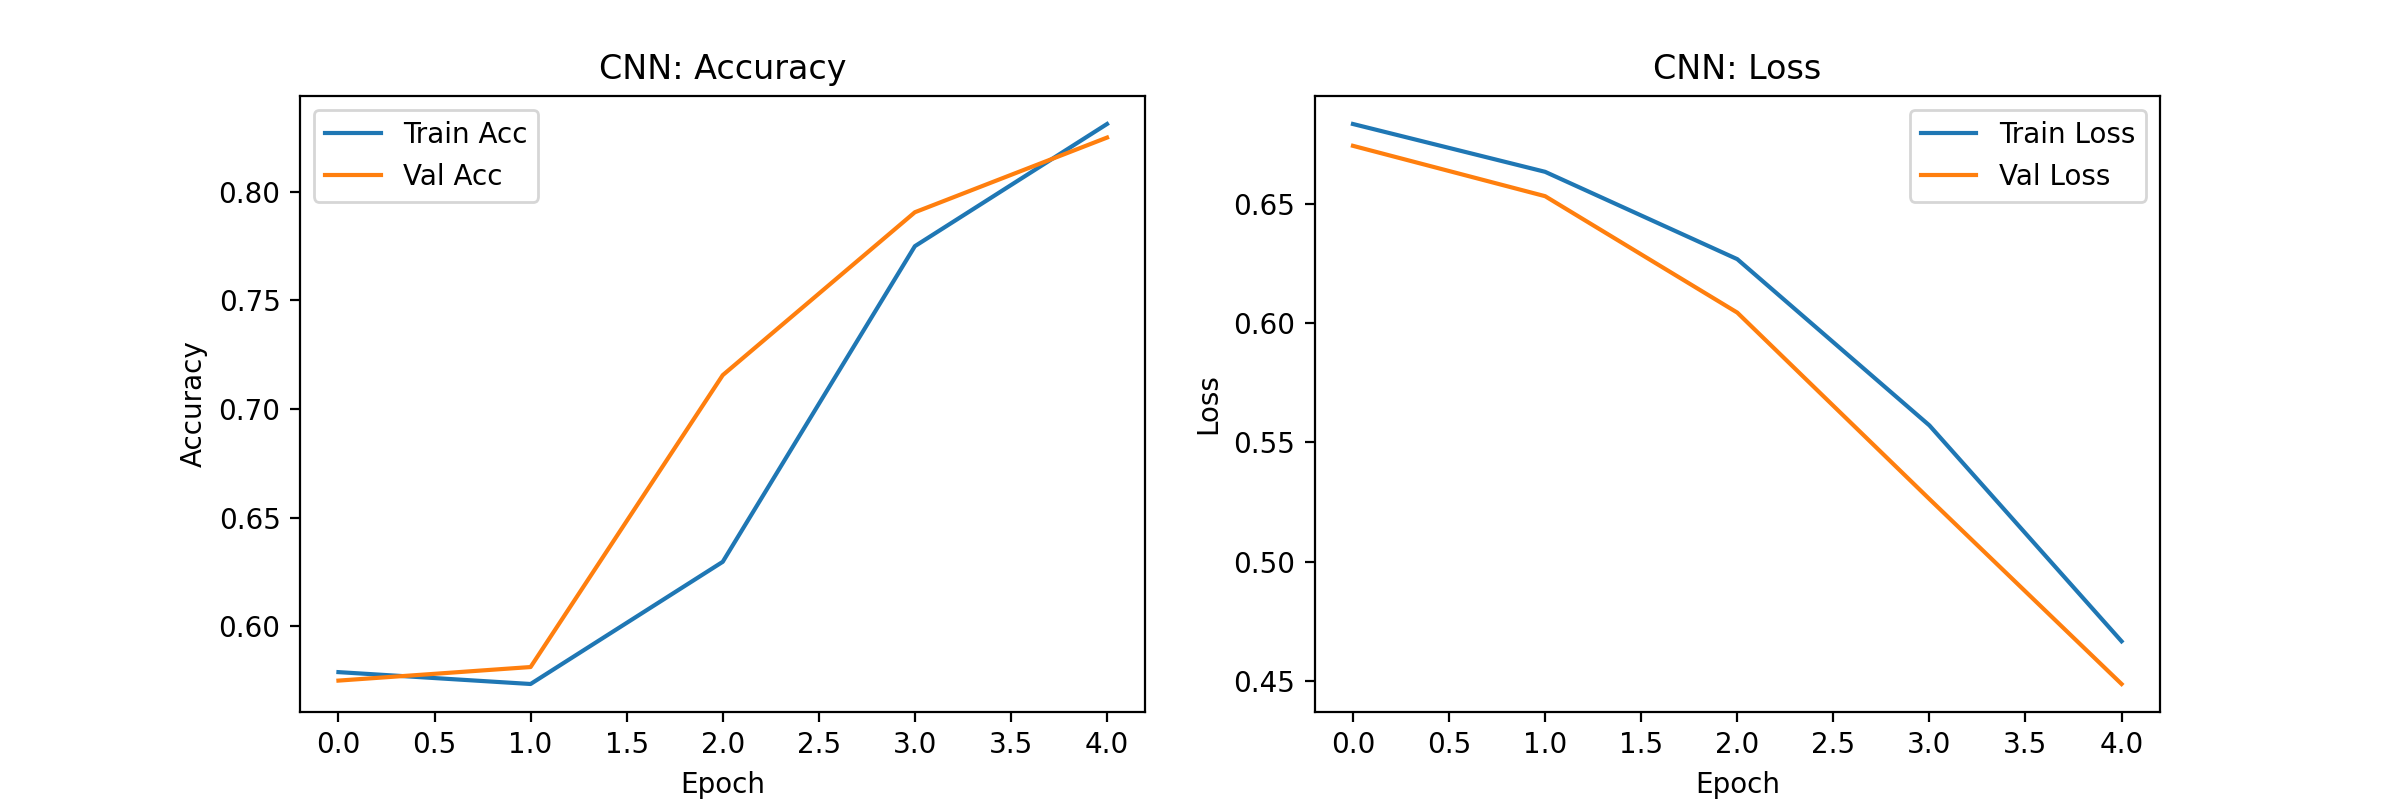

13/13 [==============================] - 0s 1ms/step - loss: 0.4540 - accuracy: 0.8200
CNN - Test Loss: 0.4540, Test Acc: 0.8200


In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1,2,1)
plt.plot(history_cnn.history['accuracy'], label='Train Acc')
plt.plot(history_cnn.history['val_accuracy'], label='Val Acc')
plt.title('CNN: Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history_cnn.history['loss'], label='Train Loss')
plt.plot(history_cnn.history['val_loss'], label='Val Loss')
plt.title('CNN: Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Evaluate on test
loss_cnn, acc_cnn = cnn_model.evaluate(X_test, y_test)
print(f"CNN - Test Loss: {loss_cnn:.4f}, Test Acc: {acc_cnn:.4f}")

## 6. Transformers Example
Now, we’ll **infer** on a few sample sentences using a **pretrained** Hugging Face pipeline. 

In [12]:
# Run this cell if needed

# !pip install --upgrade pip
# !pip install --upgrade transformers
# !python -m pip uninstall pyserial --yes
# !pip install --ignore-installed Pillow==9.0.0
# !python -m pip uninstall torchvision --yes
# !pip install --upgrade torch torchvision


  Using cached Pillow-9.0.0-cp39-cp39-macosx_10_10_x86_64.whl.metadata (7.6 kB)
Using cached Pillow-9.0.0-cp39-cp39-macosx_10_10_x86_64.whl (3.0 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
paddlepaddle 2.6.2 requires protobuf>=3.20.2; platform_system != "Windows", but you have protobuf 3.19.6 which is incompatible.
tkhtmlview 0.3.1 requires Pillow<11,>=10, but you have pillow 9.0.0 which is incompatible.
Found existing installation: torchvision 0.17.2
Uninstalling torchvision-0.17.2:
  Successfully uninstalled torchvision-0.17.2
  Using cached torchvision-0.17.2-cp39-cp39-macosx_10_13_x86_64.whl.metadata (6.6 kB)
Using cached torchvision-0.17.2-cp39-cp39-macosx_10_13_x86_64.whl (1.7 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency confl

In [13]:
import PIL
print(PIL.__version__)

import torch
import torchvision
print("torch version:", torch.__version__)
print("torchvision version:", torchvision.__version__)

9.0.0
torch version: 2.2.2
torchvision version: 0.17.2


In [16]:
from transformers import pipeline

# Load a sentiment-analysis pipeline
classifier = pipeline(
    "sentiment-analysis", 
    model="distilbert-base-uncased-finetuned-sst-2-english"
)

sentences = [
    "I love this product! It works great.",
    "This is the worst experience I've ever had.",
    "I'm fairly neutral about the results.",
    "I can't wait to use this again!"
]

results = classifier(sentences)
for sent, res in zip(sentences, results):
    print(f"Sentence: {sent}\nPrediction: {res}\n")

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Device set to use mps:0


Sentence: I love this product! It works great.
Prediction: {'label': 'POSITIVE', 'score': 0.9998793601989746}

Sentence: This is the worst experience I've ever had.
Prediction: {'label': 'NEGATIVE', 'score': 0.9997679591178894}

Sentence: I'm fairly neutral about the results.
Prediction: {'label': 'NEGATIVE', 'score': 0.9987831711769104}

Sentence: I can't wait to use this again!
Prediction: {'label': 'NEGATIVE', 'score': 0.8889403343200684}

